In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

path = "../data/realized_variance_futures_20261030/realized_variance_futures_20261030.csv"   # futures: replace "forex" with "futures" in both places
df = pd.read_csv(path, parse_dates=["date"]).sort_values(["symbol", "date"])
df.head()

,date,symbol,asset_type,open_price,close_price,high_price,low_price,pr,gkr,rr5,...,medrv1,medrv5,medrv5_ss,minrv1,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss
0,2009-09-28,C,futures,333.500,340.375,343.375,329.125,0.000648,0.000737,0.000368,...,0.000615,0.000297,0.000452,0.000579,0.000280,0.000441,0.000558,1.828195e-06,7.854140e-07,1.146453e-06
1,2009-09-29,C,futures,340.500,339.250,346.375,336.375,0.000310,0.000424,0.000430,...,0.000537,0.000592,0.000603,0.000505,0.000585,0.000625,0.000633,1.424698e-06,1.142489e-06,1.352243e-06
2,2009-09-30,C,futures,339.250,341.875,344.125,335.625,0.000226,0.000290,0.000397,...,0.000534,0.000489,0.000524,0.000522,0.000510,0.000546,0.000579,1.371340e-06,9.166120e-07,1.041591e-06
3,2009-10-01,C,futures,341.750,339.875,345.875,337.375,0.000223,0.000298,0.000274,...,0.000295,0.000378,0.000322,0.000295,0.000387,0.000300,0.000302,1.002618e-06,1.152682e-06,5.379777e-07
4,2009-10-02,C,futures,339.625,333.625,340.125,331.875,0.000217,0.000179,0.000198,...,0.000285,0.000206,0.000175,0.000255,0.000191,0.000147,0.000280,2.610137e-07,6.898027e-07,2.929334e-07


In [3]:
print(df.shape)
print(df.groupby("symbol")["date"].agg(["count", "min", "max"]))

df["gap"] = df.groupby("symbol")["date"].diff().dt.days
df[df["gap"] > 5][["date", "symbol", "gap"]]

(22028, 32)
        count        min        max
symbol                             
C        4377 2009-09-28 2026-10-30
CL       4417 2009-09-28 2026-10-30
ES       4419 2009-09-30 2026-10-30
GC       4400 2009-09-28 2026-10-30
NG       4415 2009-09-28 2026-10-30


,date,symbol,gap
13228,2009-10-28,GC,9.0
13269,2009-12-29,GC,6.0
13306,2010-02-24,GC,6.0
13344,2010-04-27,GC,8.0


In [4]:
print(df.isna().sum().sum())
print((df["rv5"] <= 0).sum())
print((df[["open_price", "close_price", "high_price", "low_price"]] <= 0).sum())

5
0
open_price     0
close_price    0
high_price     0
low_price      0
dtype: int64


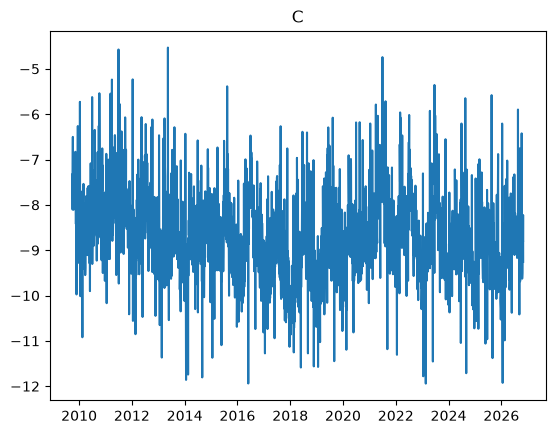

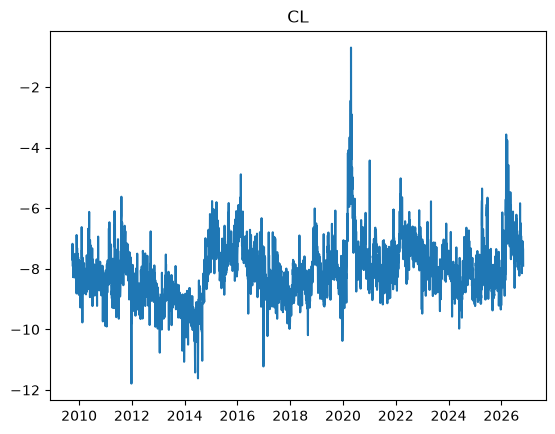

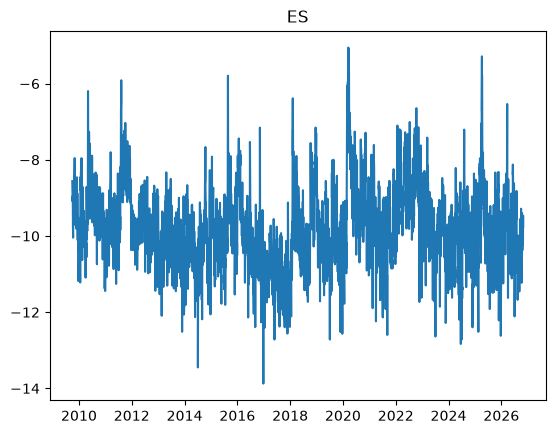

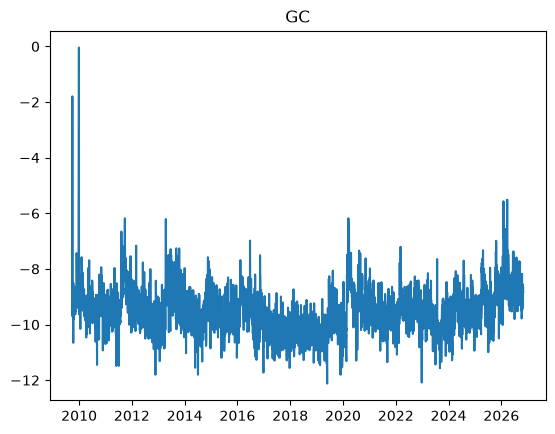

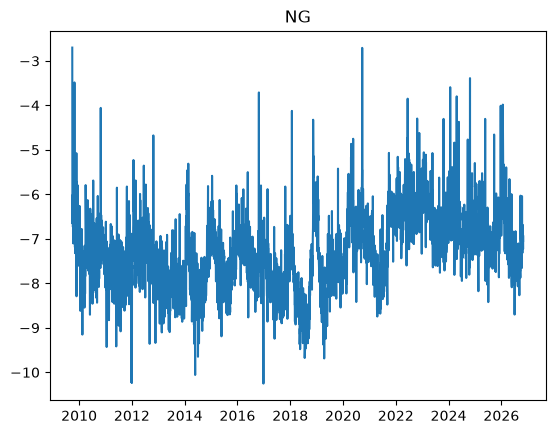

In [5]:
df["log_rv5"] = np.log(df["rv5"])
for s, g in df.groupby("symbol"):
    plt.figure()
    plt.plot(g["date"], g["log_rv5"])
    plt.title(s)

In [6]:
df["rel"] = df["rv5"] / df.groupby("symbol")["rv5"].transform("median")
df.sort_values("rel", ascending=False).groupby("symbol").head(3)[["date", "symbol", "rel", "rv5"]]

,date,symbol,rel,rv5
13269,2009-12-29,GC,14062.958423,0.959190
13214,2009-09-29,GC,2433.401702,0.165975
7105,2020-04-21,CL,1615.070885,0.498668
7102,2020-04-16,CL,280.704272,0.086670
7106,2020-04-22,CL,250.428610,0.077322
11496,2020-03-16,ES,122.421351,0.006379
11501,2020-03-23,ES,118.594876,0.006180
11494,2020-03-12,ES,106.067349,0.005527
17613,2009-09-28,NG,101.140925,0.067167
20450,2020-09-23,NG,100.489993,0.066734


In [8]:
for k in [1, 5, 22]:
    print(k, df.groupby("symbol")["log_rv5"].apply(lambda s: s.autocorr(lag=k)).round(2).to_dict())

1 {'C': 0.56, 'CL': 0.84, 'ES': 0.81, 'GC': 0.64, 'NG': 0.74}
5 {'C': 0.47, 'CL': 0.74, 'ES': 0.63, 'GC': 0.55, 'NG': 0.72}
22 {'C': 0.36, 'CL': 0.58, 'ES': 0.39, 'GC': 0.38, 'NG': 0.59}


In [9]:
df["move"] = df.groupby("symbol")["close_price"].pct_change().abs()
df["range"] = (df["high_price"] - df["low_price"]) / df["close_price"]

df.sort_values("move", ascending=False).groupby("symbol").head(3)[["date", "symbol", "close_price", "move", "rv5", "rel"]]
df.sort_values("range", ascending=False).groupby("symbol").head(3)[["date", "symbol", "range", "rv5", "rel"]]

,date,symbol,range,rv5,rel
7105,2020-04-21,CL,1.352808,0.498668,1615.070885
4429,2009-12-09,CL,0.545271,0.000555,1.799030
4411,2009-11-13,CL,0.516515,0.000382,1.235747
13269,2009-12-29,GC,0.510529,0.959190,14062.958423
17634,2009-10-27,NG,0.509596,0.001101,1.658455
17648,2009-11-16,NG,0.508079,0.001233,1.856560
11763,2021-03-29,ES,0.501387,0.000086,1.653739
20450,2020-09-23,NG,0.358875,0.066734,100.489993
13306,2010-02-24,GC,0.258441,0.000185,2.713343
13242,2009-11-17,GC,0.255330,0.000099,1.449350


In [10]:
df["range"] = (df["high_price"] - df["low_price"]) / df["close_price"]
sus = df[(df["range"] > 0.15) & (df["rel"] < 10)]   # for forex use 0.05
print(sus.groupby("symbol").size())
sus[["date", "symbol", "range", "rel"]]

symbol
CL     3
ES     1
GC     3
NG    10
dtype: int64


,date,symbol,range,rel
4394,2009-10-21,CL,0.509393,1.669954
4411,2009-11-13,CL,0.516515,1.235747
4429,2009-12-09,CL,0.545271,1.799030
11763,2021-03-29,ES,0.501387,1.653739
13242,2009-11-17,GC,0.255330,1.449350
13306,2010-02-24,GC,0.258441,2.713343
15390,2018-03-26,GC,0.252004,0.360162
17634,2009-10-27,NG,0.509596,1.658455
17648,2009-11-16,NG,0.508079,1.856560
17689,2010-01-14,NG,0.289618,1.475135


In [11]:
df[df["gap"] > 5][["date", "symbol", "gap"]]            # missing stretches (futures has uneven row counts)
df[df["date"] == "2023-01-24"][["symbol", "rel", "range"]]   # was that date strange across assets?

,symbol,rel,range
3411,C,0.714581,0.018386
7820,CL,1.325373,0.031731
12237,ES,2.046578,0.010274
16639,GC,1.007903,0.013188
21054,NG,9.598541,0.195345


In [12]:
df[df["gap"] > 5][["date", "symbol", "gap"]]

,date,symbol,gap
13228,2009-10-28,GC,9.0
13269,2009-12-29,GC,6.0
13306,2010-02-24,GC,6.0
13344,2010-04-27,GC,8.0


In [13]:
es_dates = set(df[df["symbol"] == "ES"]["date"])
c_dates = set(df[df["symbol"] == "C"]["date"])
sorted(es_dates - c_dates)[:20]

[Timestamp('2010-04-02 00:00:00'),
 Timestamp('2010-05-14 00:00:00'),
 Timestamp('2010-07-05 00:00:00'),
 Timestamp('2010-09-06 00:00:00'),
 Timestamp('2011-05-13 00:00:00'),
 Timestamp('2011-09-05 00:00:00'),
 Timestamp('2012-04-06 00:00:00'),
 Timestamp('2012-07-04 00:00:00'),
 Timestamp('2012-09-03 00:00:00'),
 Timestamp('2012-11-22 00:00:00'),
 Timestamp('2013-07-04 00:00:00'),
 Timestamp('2013-11-28 00:00:00'),
 Timestamp('2014-07-04 00:00:00'),
 Timestamp('2014-11-27 00:00:00'),
 Timestamp('2015-04-03 00:00:00'),
 Timestamp('2015-07-03 00:00:00'),
 Timestamp('2015-11-26 00:00:00'),
 Timestamp('2016-07-04 00:00:00'),
 Timestamp('2016-11-24 00:00:00'),
 Timestamp('2017-07-04 00:00:00')]